# Coupled run: climate model → river discharge for Japan

**What was done.** Ten years of daily weather from **HiRO-ACE** (an AI climate emulator) were
aggregated onto Japan's river catchments and fed to the **trained discharge model**, which
produced daily river flow at 962 gauged rivers. This is the first end-to-end run of the chain:
nothing in the river model saw real weather during this run.

**How to read the comparison.** HiRO-ACE simulates *a* plausible climate, not the actual
2015–2020 weather, so a flood on a given date in the simulation is not the real flood on that
date. We therefore compare each river's **character** (how much water it carries on average,
when in the year it runs high, how sharply it responds to rain) and never individual events.

Three figures:
1. **Where:** all 962 gauges, coloured by how well the average flow is reproduced.
2. **How well:** predicted vs observed average flow, for rivers spanning four orders of magnitude.
3. **How it works:** one simulated year at two rivers, with the climate model's precipitation
   above the river flow it produces.

Details and caveats: `coupled_run_diagnostics.ipynb` in this folder.

In [1]:
from pathlib import Path
import urllib.request
import numpy as np, pandas as pd, xarray as xr, geopandas as gpd, networkx as nx
import matplotlib.pyplot as plt, matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm

DATA = Path("/Users/valentin/Desktop/UNRISK/Projects/coupled_model/climate-hydro-pipeline-data")
RUN = DATA / "hydro/results/coupled_run_2026-09-23"
FORCING = DATA / "processing/catchment_weighting/data/hiroace_dynamic_ic0000_full10yr_m0_v2.zarr"
GRAPH = DATA / "hydro/data/g.pkl"                  # river network (copy of Japan_routing/data/g.pkl)
LAND = DATA / "reference/ne_50m_land.zip"          # Natural Earth coastline, downloaded once
FIGS = Path("../figures"); SAVE = False             # SAVE = True writes PNGs for slides

SURFACE, INK, INK2, INK3 = "#fcfcfb", "#0b0b0b", "#52514e", "#8a8983"
BLUE, AQUA, RED, MID = "#2a78d6", "#1baf7a", "#e34948", "#f0efec"
plt.rcParams.update({"figure.dpi": 130, "savefig.dpi": 200, "figure.facecolor": SURFACE,
                     "axes.facecolor": SURFACE, "axes.edgecolor": INK3, "axes.labelcolor": INK2,
                     "text.color": INK, "xtick.color": INK2, "ytick.color": INK2,
                     "axes.grid": True, "grid.color": "#e6e5e0", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})

def style(ax, title=None, ylabel=None, xlabel=None):
    if title: ax.set_title(title, color=INK, fontsize=12, fontweight="bold", loc="left", pad=10)
    if ylabel: ax.set_ylabel(ylabel)
    if xlabel: ax.set_xlabel(xlabel)
    ax.set_axisbelow(True)
    return ax

def save(fig, name):
    if SAVE:
        FIGS.mkdir(exist_ok=True); fig.savefig(FIGS / f"{name}.png", bbox_inches="tight")

# --- load, aligned by catchment ID (files store catchments in different orders) --------------
obs = xr.open_dataset(RUN / "observed_discharge_gauged.nc")["discharge_obs"].transpose("spatial", "time")
nodes = obs["spatial"].values
pred = (xr.open_dataset(RUN / "predictions_hiroace_full10yr_m0_frozen.nc")["discharge_pred"]
          .sel(spatial=nodes).transpose("spatial", "time"))
meta = pd.read_csv(RUN / "gauged_catchment_meta.csv").set_index("node").loc[nodes]
flags = pd.read_csv(RUN / "catchment_training_flags.csv").set_index("node").loc[nodes]
stats = pd.read_csv(RUN / "pred_vs_obs_stats_frozen.csv").set_index("node").loc[nodes]
s = stats.assign(lat=meta["lat"], lon=meta["lon"], n_up=flags["n_upstream"], dam_free=flags["in_training"])

# gauges with at least a year of observations: the set used in figures 1 and 2
keep = (s["obs_n_valid"] >= 365) & (s["obs_mean"] > 0)
ratio = s.loc[keep, "ratio_mean"]
print(f"gauges compared: {keep.sum()} of {len(s)}")
print(f"median mean-flow ratio {ratio.median():.2f} | within a factor of 1.5: "
      f"{100 * ratio.between(1/1.5, 1.5).mean():.0f}% | within a factor of 2: {100 * ratio.between(.5, 2).mean():.0f}%")

# --- the two rivers in figure 3, picked by rule ------------------------------------------------
# Both are dam-free headwaters (≤1 upstream catchment), so the river responds directly to the
# precipitation shown, with average flow within ±15% of observed.
# A: the largest such river in the rain-fed south. B: the one receiving the most HiRO-ACE snowfall
# (~600 mm/yr falls below 0 °C; ranked in a side check, pinned here by node).
good = (s["obs_n_valid"] >= .9 * obs.sizes["time"]) & (s["obs_mean"] > 0)
cand = s[good & s["dam_free"] & (s["n_up"] <= 1) & s["ratio_mean"].between(.85, 1.15)]
GAUGES = {"A": ("Rain-fed river, central Honshu", cand[cand["lat"] < 36]["obs_mean"].idxmax()),
          "B": ("Snow-fed river, central Hokkaido", 647336107)}
for k, (name, n) in GAUGES.items():
    r = s.loc[n]
    print(f"{k}: {name:34s} node {n}  {r.lat:.2f}°N {r.lon:.2f}°E  mean obs {r.obs_mean:.2f} "
          f"pred {r.pred_mean:.2f} m³/s")

gauges compared: 952 of 962
median mean-flow ratio 1.20 | within a factor of 1.5: 73% | within a factor of 2: 91%
A: Rain-fed river, central Honshu     node 2552973078  35.01°N 138.27°E  mean obs 10.12 pred 9.32 m³/s
B: Snow-fed river, central Hokkaido   node 647336107  43.21°N 142.06°E  mean obs 2.72 pred 2.70 m³/s


## 1. The coupled chain runs across the whole country

Each dot is a river gauge. Colour compares the **average flow** the model predicts from HiRO-ACE
weather with the average flow actually measured there (the *mean-flow ratio*,
predicted ÷ observed): grey means about right, red too much water, blue too little.

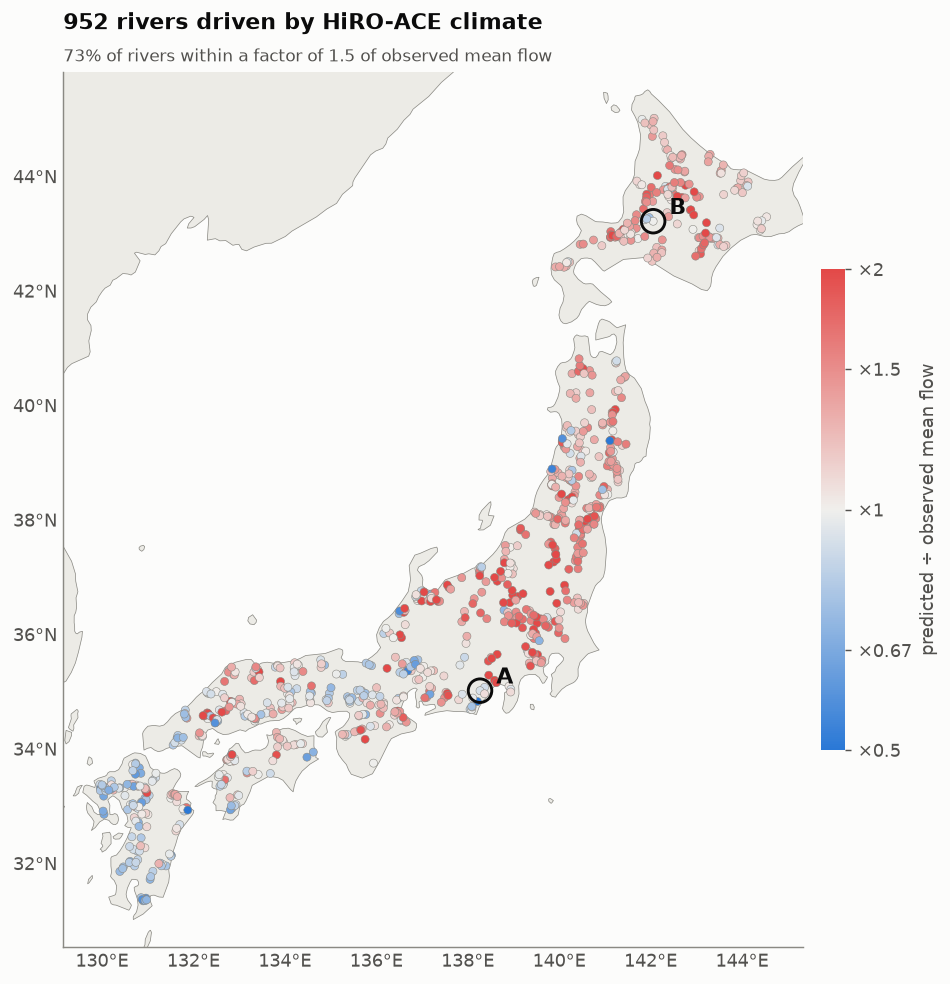

In [2]:
if not LAND.exists():
    LAND.parent.mkdir(parents=True, exist_ok=True)
    urllib.request.urlretrieve("https://naciscdn.org/naturalearth/50m/physical/ne_50m_land.zip", LAND)
land = gpd.read_file(LAND)

d = s[keep]
div = LinearSegmentedColormap.from_list("blue_gray_red", [BLUE, MID, RED])
fig, ax = plt.subplots(figsize=(7.6, 7.6))
land.plot(ax=ax, color="#ecebe6", edgecolor=INK3, linewidth=.4, zorder=0)
sc = ax.scatter(d["lon"], d["lat"], c=np.log2(d["ratio_mean"]), cmap=div, norm=TwoSlopeNorm(0, -1, 1),
                s=20, edgecolors=INK3, linewidths=.3, zorder=2)
for k, (name, n) in GAUGES.items():
    ax.scatter(s.loc[n, "lon"], s.loc[n, "lat"], s=170, facecolors="none", edgecolors=INK, lw=1.6, zorder=3)
    ax.annotate(k, (s.loc[n, "lon"], s.loc[n, "lat"]), xytext=(9, 4), textcoords="offset points",
                fontsize=12, fontweight="bold", color=INK, zorder=3)
pad = .8
ax.set_xlim(d["lon"].min() - pad, d["lon"].max() + pad); ax.set_ylim(d["lat"].min() - pad, d["lat"].max() + pad)
ax.set_aspect(1 / np.cos(np.deg2rad(37)))
ax.grid(False); ax.tick_params(length=0)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}°E"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:g}°N"))
cb = fig.colorbar(sc, ax=ax, shrink=.55, pad=.02)
cb.set_ticks(np.log2([.5, 1/1.5, 1, 1.5, 2])); cb.set_ticklabels(["×0.5", "×0.67", "×1", "×1.5", "×2"])
cb.set_label("predicted ÷ observed mean flow", color=INK2); cb.outline.set_visible(False)
ax.set_title(f"{len(d)} rivers driven by HiRO-ACE climate", color=INK, fontsize=12, fontweight="bold", loc="left", pad=24)
ax.text(0, 1.008, f"{100 * ratio.between(1/1.5, 1.5).mean():.0f}% of rivers within a factor of 1.5 of observed mean flow",
        transform=ax.transAxes, color=INK2, fontsize=9.5, va="bottom")
fig.tight_layout(); save(fig, "1_map_mean_flow_ratio")

## 2. Each river carries about the right amount of water

The same rivers as a scatter: observed average flow along the bottom, predicted along the side.
They range from trickles of 0.2 m³/s to rivers of ~1,000 m³/s; a perfect prediction sits on the
dashed line, and the shaded band is "within a factor of 2". Both axes are logarithmic so that
small and large rivers fit on one plot. This makes the ~20% over-prediction seen in the map
look small: every point is shifted up by the same proportion, which is only a short distance on
an axis spanning four orders of magnitude. The model is not told how big each
river is: it gets that from the climate-model weather and the catchment's landscape.

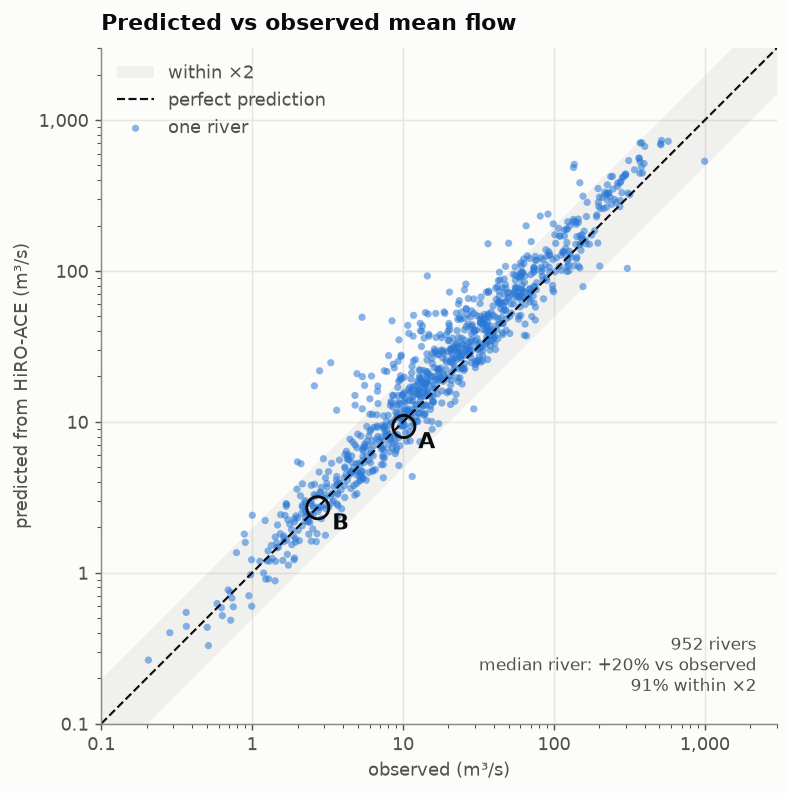

In [3]:
fig, ax = plt.subplots(figsize=(6.6, 6.2))
lo, hi = .1, 3000
ax.fill_between([lo, hi], [lo / 2, hi / 2], [lo * 2, hi * 2], color=INK3, alpha=.1, lw=0, label="within ×2")
ax.plot([lo, hi], [lo, hi], color=INK, lw=1.2, ls="--", label="perfect prediction")
ax.scatter(d["obs_mean"], d["pred_mean"], s=16, color=BLUE, alpha=.55, edgecolors="none", label="one river")
for k, (name, n) in GAUGES.items():
    ax.scatter(s.loc[n, "obs_mean"], s.loc[n, "pred_mean"], s=150, facecolors="none", edgecolors=INK, lw=1.6)
    ax.annotate(k, (s.loc[n, "obs_mean"], s.loc[n, "pred_mean"]), xytext=(8, -12),
                textcoords="offset points", fontsize=12, fontweight="bold")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lo, hi); ax.set_ylim(lo, hi); ax.set_aspect("equal")
fmt = plt.FuncFormatter(lambda v, _: f"{v:,g}")
ax.xaxis.set_major_formatter(fmt); ax.yaxis.set_major_formatter(fmt)
style(ax, "Predicted vs observed mean flow", "predicted from HiRO-ACE (m³/s)", "observed (m³/s)")
ax.text(.97, .04, f"{len(d)} rivers\nmedian river: {100 * (ratio.median() - 1):+.0f}% vs observed\n{100 * ratio.between(.5, 2).mean():.0f}% within ×2",
        transform=ax.transAxes, ha="right", va="bottom", color=INK2, fontsize=9.5)
ax.legend(frameon=False, labelcolor=INK2, loc="upper left")
fig.tight_layout(); save(fig, "2_scatter_mean_flow")

## 3. Climate-model precipitation becomes river flow

One simulated year at rivers **A** and **B** (ringed above). Top of each panel: daily
precipitation that HiRO-ACE produced, averaged over **the whole area draining to the gauge**
(the gauge's own catchment plus everything upstream of it, weighted by area), which is all the
water the river model can route to that point. Below: the river flow the model predicts from that
weather. The simulated weather is not the real weather of any year, so there is no observed
hydrograph to overlay; figures 1 and 2 are the check against observations.

- **A** responds within a day or two to each rain event, then recedes: a typical rain-fed river.
- **B** barely responds to winter precipitation, then carries a sustained high flow through
  April–May: winter's precipitation released in spring, the snowmelt pattern typical of Hokkaido
  rivers.

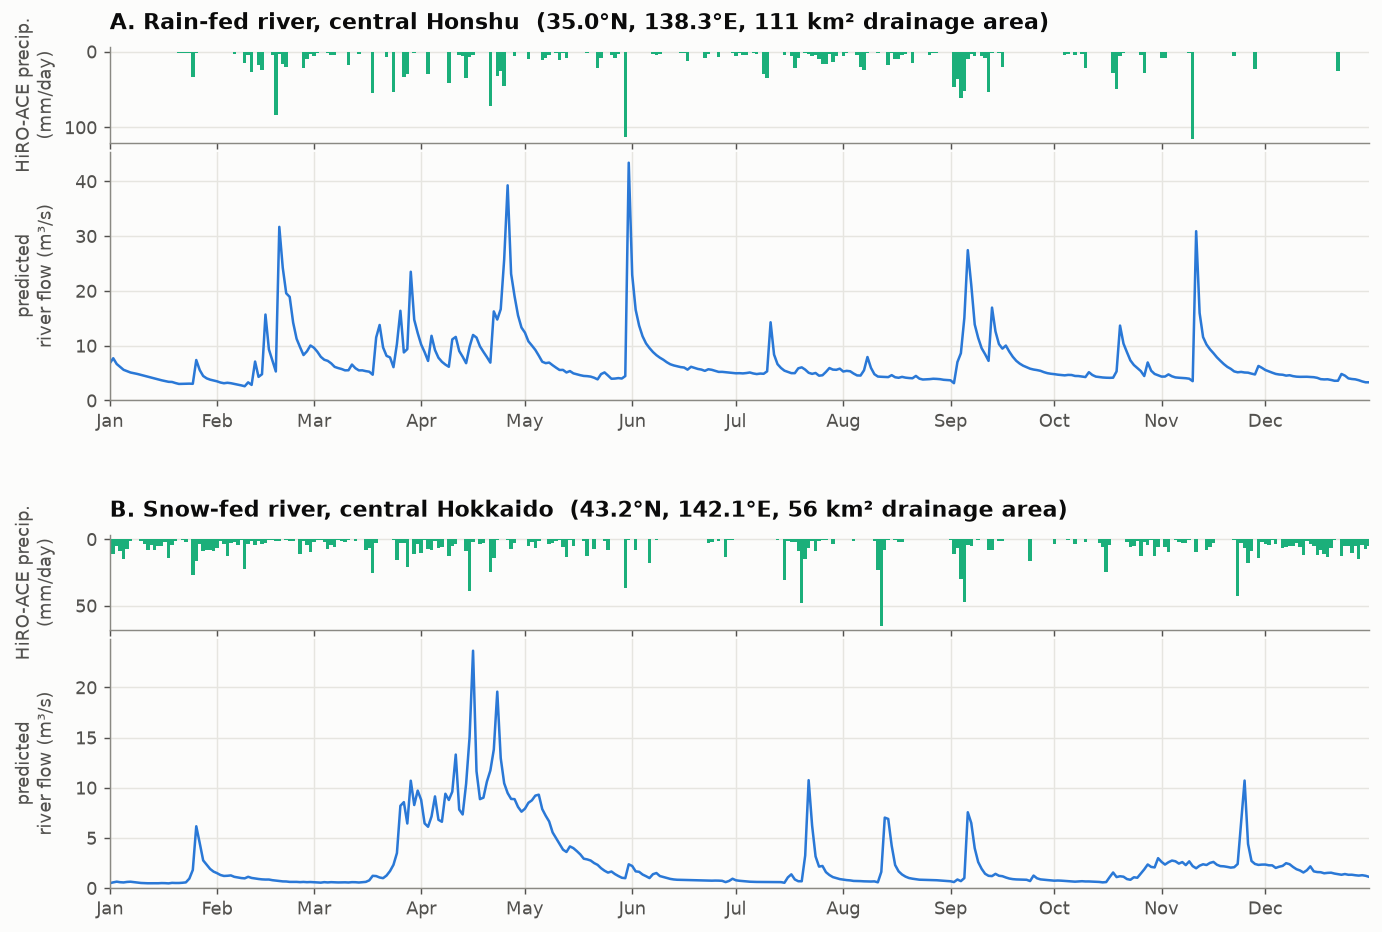

In [4]:
SIM_YEAR = 2018      # any full simulated year 2015–2022; it is not the real 2018
t0, t1 = pd.Timestamp(f"{SIM_YEAR}-01-01"), pd.Timestamp(f"{SIM_YEAR}-12-31")
g = pd.read_pickle(GRAPH)

# precipitation averaged over each gauge's full drainage area (own catchment + all upstream ones)
upstream = {n: sorted(nx.ancestors(g, n) | {n}) for _, n in GAUGES.values()}
fds = xr.open_zarr(FORCING, consolidated=None).sel(
    spatial=sorted(set().union(*upstream.values())), time=slice(t0, t1))
prcp = (sum(fds[f"hiroace_prcp_4h_bin_{b}"] for b in range(6)) / 6 * 24).to_pandas()   # mm/day, (time, catchment)
ftime = pd.DatetimeIndex(prcp.index)

def drainage_precip(n):
    up = upstream[n]
    w = np.array([g.nodes[u]["catchment_area"] for u in up])
    return prcp[up].values @ (w / w.sum()), w.sum()

pt = pd.DatetimeIndex(pred["time"].values); pm = (pt >= t0) & (pt <= t1)
fig = plt.figure(figsize=(12.5, 8.4))
outer = fig.add_gridspec(len(GAUGES), 1, hspace=.38)
for j, (k, (name, n)) in enumerate(GAUGES.items()):
    inner = outer[j].subgridspec(2, 1, height_ratios=[1, 2.6], hspace=.05)
    ra = fig.add_subplot(inner[0]); qa = fig.add_subplot(inner[1], sharex=ra)
    p, area = drainage_precip(n)
    ra.bar(ftime, p, width=1, color=AQUA, lw=0)
    ra.invert_yaxis(); ra.tick_params(labelbottom=False); ra.grid(axis="x", visible=False)
    r = s.loc[n]
    style(ra, f"{k}. {name}  ({r.lat:.1f}°N, {r.lon:.1f}°E, {area:,.0f} km² drainage area)", "HiRO-ACE precip.\n(mm/day)")

    i = int(np.where(nodes == n)[0][0])
    qa.plot(pt[pm], pred.values[i, pm], color=BLUE, lw=1.4)
    qa.set_ylim(0, None); qa.set_xlim(t0, t1)
    qa.xaxis.set_major_locator(mdates.MonthLocator()); qa.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    style(qa, None, "predicted\nriver flow (m³/s)")
fig.align_ylabels()
save(fig, "3_hydrographs_one_year")